# Save correctly and incorrectly classified images from an ONNX model

Set three paths below: the ONNX model, an image folder, and an output folder. The image folder can be either one class folder (for example, `test/fear/`) or a parent folder containing class subfolders (for example, `test/angry/` and `test/happy/`). Folder names are used as true labels.

The notebook reads `deployment_metadata.json` from beside the ONNX model. It copies classified images into `OUTPUT_DIR/<true class>/correct/` or `OUTPUT_DIR/<true class>/wrong/`, with predicted class and confidence in each filename. Correct images below `MIN_CONFIDENCE` are excluded; wrong images are all saved.

In [11]:
import json
import shutil
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import onnxruntime as ort

# Set these three paths.
ONNX_PATH = Path(r"D:\Shitol\last_codes\outputs\yolov8m\yolov8m_face_expression.onnx")
IMAGE_DIR = Path(r"D:\Research\Dataset\Multi-culture\emp_edu\fear")  # one subfolder per class
OUTPUT_DIR = Path(r"D:\Shitol\last_codes\outputs\yolov8m\correct_onnx")

# The deployment metadata is expected beside the ONNX model.
META_PATH = ONNX_PATH.with_name("deployment_metadata.json")

# ---------------- Options ----------------
MIN_CONFIDENCE = 0.0  # minimum confidence for saving correctly classified images
BATCH = 64
SHOW_PER_CLASS = 8
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

for required_path in (ONNX_PATH, META_PATH):
    if not required_path.is_file():
        raise FileNotFoundError(f"File not found: {required_path}")
if not IMAGE_DIR.is_dir():
    raise NotADirectoryError(f"Image folder not found: {IMAGE_DIR}")

with META_PATH.open(encoding="utf-8") as f:
    meta = json.load(f)
CLASS_NAMES, IMG_SIZE = meta["classes"], meta["image_size"]
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Model:", ONNX_PATH.name, "| classes:", CLASS_NAMES, "| image size:", IMG_SIZE)

Model: yolov8m_face_expression.onnx | classes: ['angry', 'fear', 'happy', 'neutral', 'sad', 'surprise'] | image size: 256


## 1. Load the ONNX model

In [12]:
providers = [p for p in ("CUDAExecutionProvider", "CPUExecutionProvider") if p in ort.get_available_providers()]
try:
    sess = ort.InferenceSession(str(ONNX_PATH), providers=providers)
except Exception as e:                        # CUDA libraries missing -> CPU
    print("CUDA provider failed, using CPU:", e)
    sess = ort.InferenceSession(str(ONNX_PATH), providers=["CPUExecutionProvider"])
INPUT_NAME = sess.get_inputs()[0].name
print("Providers:", sess.get_providers(), "| input:", INPUT_NAME, sess.get_inputs()[0].shape,
      "| output:", sess.get_outputs()[0].name, sess.get_outputs()[0].shape)

Providers: ['CPUExecutionProvider'] | input: images ['batch', 3, 256, 256] | output: probs ['batch', 6]


## 2. Read images from the class folders and predict

In [13]:
def read_bgr(path):
    # works with non-ASCII paths on Windows
    try:
        data = np.fromfile(str(path), dtype=np.uint8)
        return cv2.imdecode(data, cv2.IMREAD_COLOR) if data.size else None
    except OSError:
        return None

def onnx_prep(img, s=IMG_SIZE):
    # identical to the ONNX export cell: short side -> s, centre crop, BGR -> RGB, CHW, [0, 1]
    h, w = img.shape[:2]; f = s / min(h, w)
    img = cv2.resize(img, (max(s, round(w * f)), max(s, round(h * f))), interpolation=cv2.INTER_LINEAR)
    y0, x0 = (img.shape[0] - s) // 2, (img.shape[1] - s) // 2
    return cv2.cvtColor(img[y0:y0 + s, x0:x0 + s], cv2.COLOR_BGR2RGB).transpose(2, 0, 1).astype(np.float32) / 255

class_name_by_key = {name.casefold(): name for name in CLASS_NAMES}
if IMAGE_DIR.name.casefold() in class_name_by_key:
    class_folders = [(class_name_by_key[IMAGE_DIR.name.casefold()], IMAGE_DIR)]
else:
    class_folders = [(name, IMAGE_DIR / name) for name in CLASS_NAMES
                     if (IMAGE_DIR / name).is_dir()]
if not class_folders:
    raise ValueError(
        f"No class folders found in {IMAGE_DIR}. Set IMAGE_DIR to a class folder "
        "(for example, test/fear) or its parent folder (for example, test)."
    )

rows = [{"label": label, "image_path": str(path)}
        for label, folder in class_folders
        for path in sorted(folder.iterdir())
        if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS]
if not rows:
    raise ValueError(f"No supported images found in {IMAGE_DIR}")
df = pd.DataFrame(rows)
print(df.groupby("label").size())

probs, unreadable = np.zeros((len(df), len(CLASS_NAMES)), np.float32), []
for i in range(0, len(df), BATCH):
    idx, batch = [], []
    for j in range(i, min(i + BATCH, len(df))):
        img = read_bgr(df.at[j, "image_path"])
        if img is None:
            unreadable.append(j); continue
        idx.append(j); batch.append(onnx_prep(img))
    if batch:
        probs[idx] = sess.run(None, {INPUT_NAME: np.stack(batch)})[0]
df = df.drop(index=unreadable).reset_index(drop=True); probs = np.delete(probs, unreadable, axis=0)
if df.empty:
    raise ValueError(f"No readable images found in {IMAGE_DIR}")
print(f"Predicted {len(df)} images | unreadable: {len(unreadable)}")

label
fear    2020
dtype: int64
Predicted 2020 images | unreadable: 0


## 3. Correct vs. wrong, per class

In [14]:
df["predicted"] = np.array(CLASS_NAMES)[probs.argmax(1)]
df["confidence"] = probs.max(1)
for k, c in enumerate(CLASS_NAMES):
    df[f"p_{c}"] = probs[:, k]
df["correct"] = df["predicted"] == df["label"]

summary = (df.groupby("label")
             .agg(total=("correct", "size"), correct=("correct", "sum"),
                  mean_conf_correct=("confidence", lambda s: s[df.loc[s.index, "correct"]].mean()))
             .reset_index())
summary["wrong"] = summary["total"] - summary["correct"]
summary["accuracy"] = summary["correct"] / summary["total"]
summary = summary[["label", "correct", "wrong", "total", "accuracy", "mean_conf_correct"]]
print("Overall accuracy:", round(df["correct"].mean(), 4), "\n")
summary.style.format({"accuracy": "{:.2%}", "mean_conf_correct": "{:.3f}"}).hide(axis="index")

Overall accuracy: 0.8554 



label,correct,wrong,total,accuracy,mean_conf_correct
fear,1728,292,2020,85.54%,0.967


## 4. Save correct and wrong images into separate folders

In [15]:
correct = df[df["correct"] & (df["confidence"] >= MIN_CONFIDENCE)].copy()
wrong = df[~df["correct"]].copy()

for result, category in ((correct, "correct"), (wrong, "wrong")):
    for row in result.itertuples(index=False):
        source_path = Path(row.image_path)
        filename = f"pred-{row.predicted}_conf{row.confidence:.4f}_{source_path.name}"
        destination = OUTPUT_DIR / row.label / category / filename
        destination.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(source_path, destination)

print(f"Saved {len(correct)} correctly classified images")
print(f"Saved {len(wrong)} incorrectly classified images")
for class_name in CLASS_NAMES:
    n_correct = int((correct["label"] == class_name).sum())
    n_wrong = int((wrong["label"] == class_name).sum())
    print(f"{class_name}: {n_correct} correct, {n_wrong} wrong -> {OUTPUT_DIR / class_name}")

Saved 1728 correctly classified images
Saved 292 incorrectly classified images
angry: 0 correct, 0 wrong -> D:\Shitol\last_codes\outputs\yolov8m\correct_onnx\angry
fear: 1728 correct, 292 wrong -> D:\Shitol\last_codes\outputs\yolov8m\correct_onnx\fear
happy: 0 correct, 0 wrong -> D:\Shitol\last_codes\outputs\yolov8m\correct_onnx\happy
neutral: 0 correct, 0 wrong -> D:\Shitol\last_codes\outputs\yolov8m\correct_onnx\neutral
sad: 0 correct, 0 wrong -> D:\Shitol\last_codes\outputs\yolov8m\correct_onnx\sad
surprise: 0 correct, 0 wrong -> D:\Shitol\last_codes\outputs\yolov8m\correct_onnx\surprise


## 5. Preview correct and wrong classifications

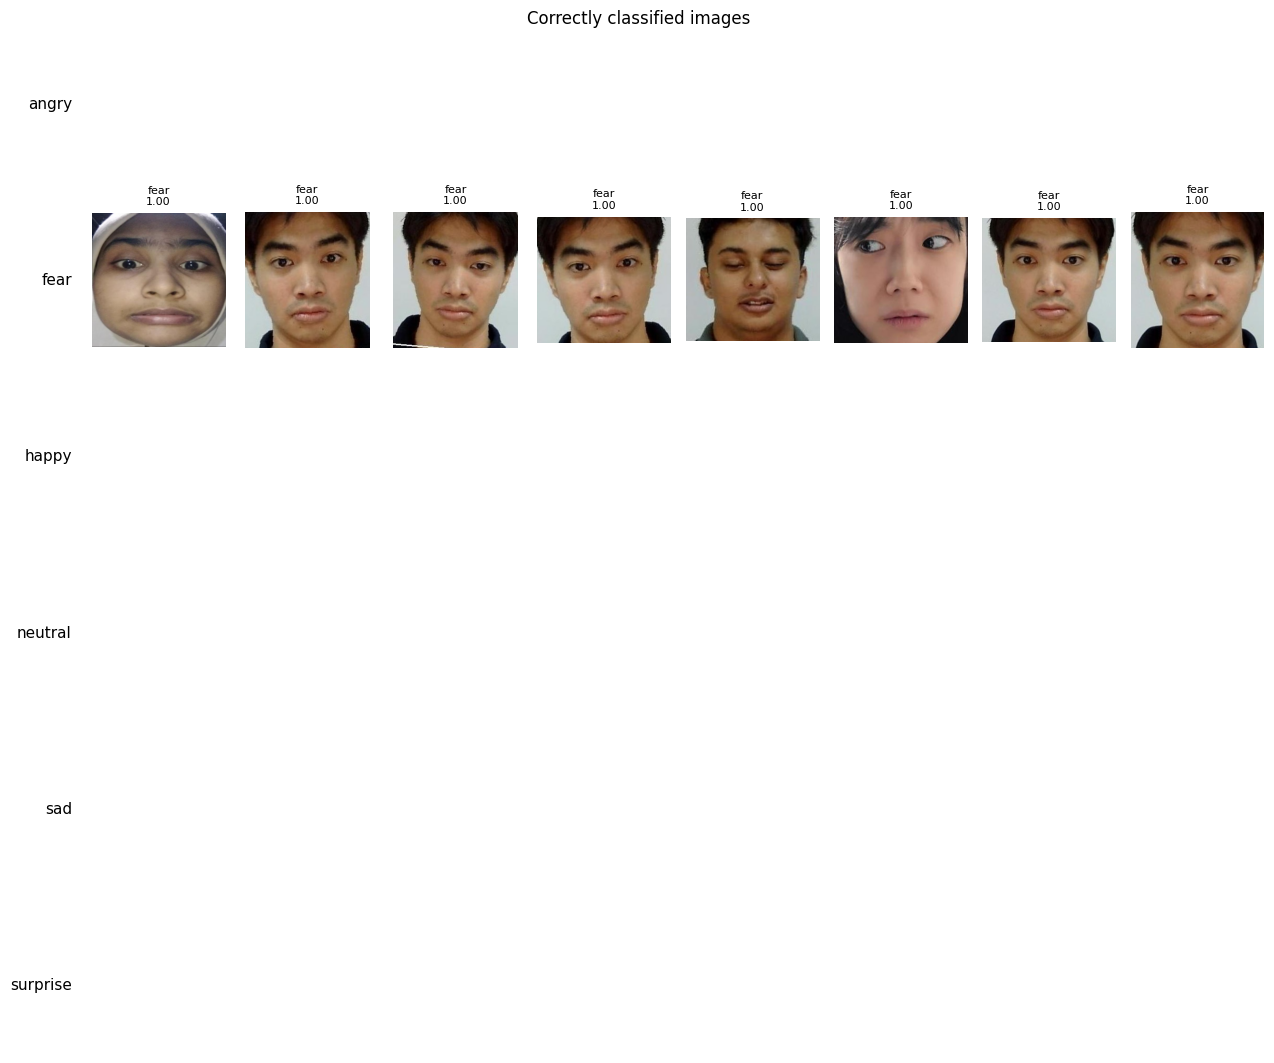

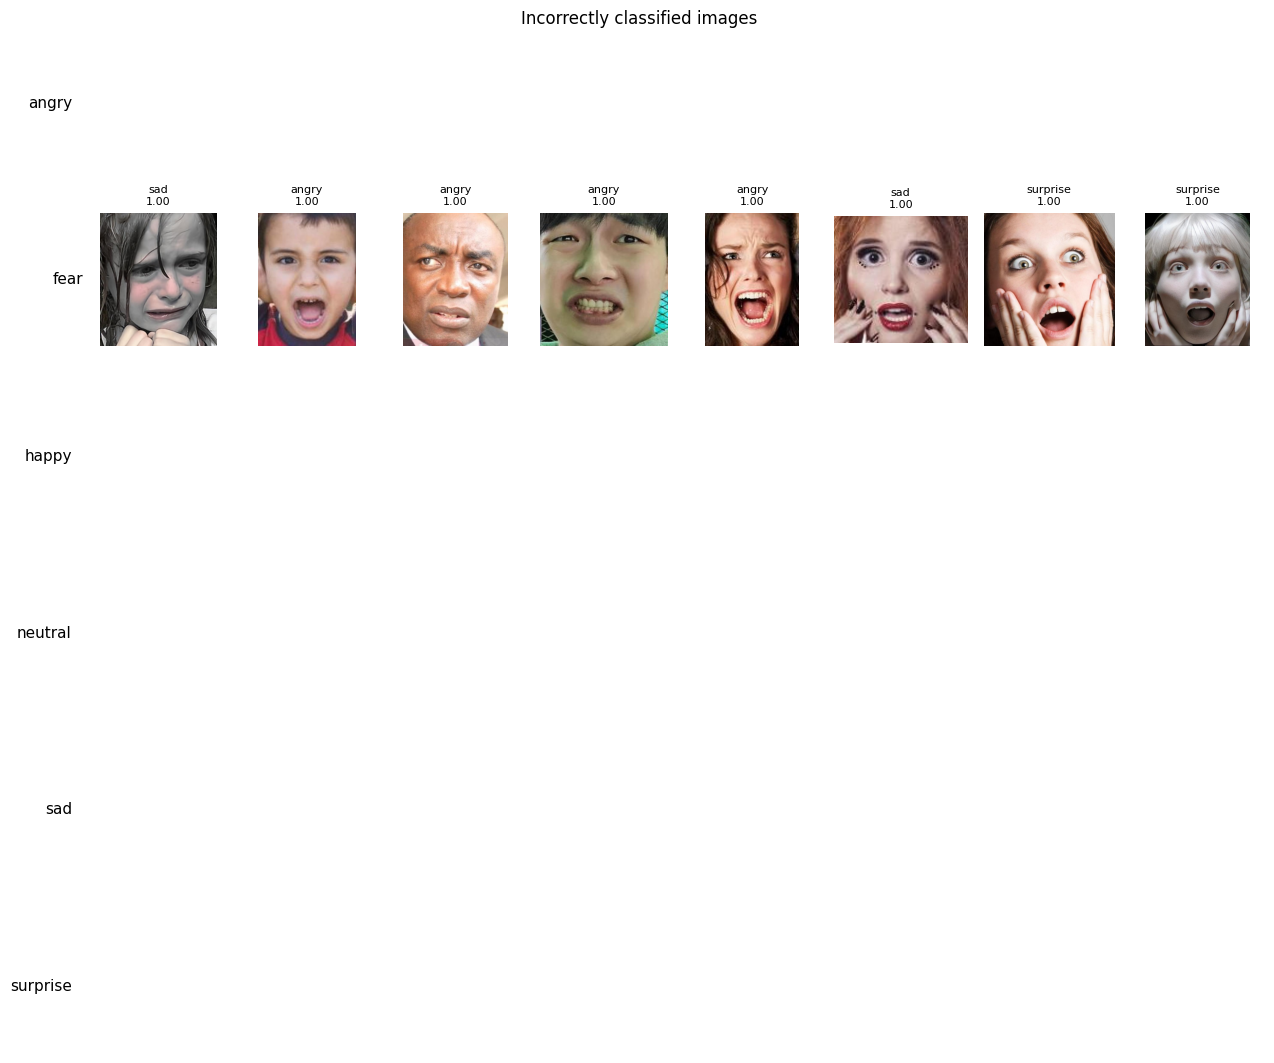

In [16]:
def show_grid(sub_df, title):
    n = SHOW_PER_CLASS
    fig, axes = plt.subplots(len(CLASS_NAMES), n, figsize=(1.6 * n, 1.8 * len(CLASS_NAMES)), squeeze=False)
    for i, c in enumerate(CLASS_NAMES):
        sub = sub_df[sub_df["label"] == c].head(n)
        for j in range(n):
            ax = axes[i, j]; ax.axis("off")
            if j < len(sub):
                r = sub.iloc[j]
                img = read_bgr(r["image_path"])
                if img is not None:
                    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
                ax.set_title(f"{r['predicted']}\n{r['confidence']:.2f}", fontsize=8)
        axes[i, 0].text(-0.15, 0.5, c, transform=axes[i, 0].transAxes, ha="right", va="center", fontsize=11)
    plt.suptitle(title); plt.tight_layout(); plt.show()

show_grid(correct.sort_values("confidence", ascending=False), "Correctly classified images")
show_grid(wrong.sort_values("confidence", ascending=False), "Incorrectly classified images")

## 6. Look up correct images for one class

In [17]:
CLASS = "fear"  # choose any class in CLASS_NAMES
sel = correct[correct["label"] == CLASS]
print(f"{CLASS}: {len(sel)} correctly classified images")
sel[["image_path", "predicted", "confidence"]].head(20)

fear: 1728 correctly classified images


,image_path,predicted,confidence
1,D:\Research\Dataset\Multi-culture\emp_edu\fear...,fear,0.531289
3,D:\Research\Dataset\Multi-culture\emp_edu\fear...,fear,0.935478
4,D:\Research\Dataset\Multi-culture\emp_edu\fear...,fear,0.990074
5,D:\Research\Dataset\Multi-culture\emp_edu\fear...,fear,0.999094
6,D:\Research\Dataset\Multi-culture\emp_edu\fear...,fear,0.988156
7,D:\Research\Dataset\Multi-culture\emp_edu\fear...,fear,0.978830
8,D:\Research\Dataset\Multi-culture\emp_edu\fear...,fear,0.999966
9,D:\Research\Dataset\Multi-culture\emp_edu\fear...,fear,0.870527
10,D:\Research\Dataset\Multi-culture\emp_edu\fear...,fear,0.999995
11,D:\Research\Dataset\Multi-culture\emp_edu\fear...,fear,0.999960
